# Smart Battery Manager - TinyML
**IoT Project 2026** - Dario Falaschi & Leonardo Lentini


### 1. Data Loading and Preparation
*Remember to upload the `Plant_1_Generation_Data.csv`, `Plant_1_Weather_Sensor_Data.csv`, `Plant_2_Generation_Data.csv`, and `Plant_2_Weather_Sensor_Data.csv` files to the file panel on the left.*

In [15]:
import pandas as pd
import numpy as np

# --- PLANT 1 PROCESSING ---
df_gen_1 = pd.read_csv('Plant_1_Generation_Data.csv')
df_weather_1 = pd.read_csv('Plant_1_Weather_Sensor_Data.csv')

# Plant 1 uses a specific date format
df_gen_1['DATE_TIME'] = pd.to_datetime(df_gen_1['DATE_TIME'], format='%d-%m-%Y %H:%M')
df_weather_1['DATE_TIME'] = pd.to_datetime(df_weather_1['DATE_TIME'])

# Filter by a single inverter to maintain a coherent time-series
inverter_id_1 = df_gen_1['SOURCE_KEY'].unique()[0]
df_gen_filtered_1 = df_gen_1[df_gen_1['SOURCE_KEY'] == inverter_id_1].copy()

# Merge generation and weather data
df_merged_1 = pd.merge(df_gen_filtered_1, df_weather_1, on='DATE_TIME', how='inner')
target_columns = ['DATE_TIME', 'AC_POWER', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
df_1 = df_merged_1[target_columns].sort_values('DATE_TIME').reset_index(drop=True)


# --- PLANT 2 PROCESSING ---
df_gen_2 = pd.read_csv('Plant_2_Generation_Data.csv')
df_weather_2 = pd.read_csv('Plant_2_Weather_Sensor_Data.csv')

# Plant 2 uses a different date format (usually Year-Month-Day)
df_gen_2['DATE_TIME'] = pd.to_datetime(df_gen_2['DATE_TIME'])
df_weather_2['DATE_TIME'] = pd.to_datetime(df_weather_2['DATE_TIME'])

# Filter by a single inverter
inverter_id_2 = df_gen_2['SOURCE_KEY'].unique()[0]
df_gen_filtered_2 = df_gen_2[df_gen_2['SOURCE_KEY'] == inverter_id_2].copy()

# Merge generation and weather data
df_merged_2 = pd.merge(df_gen_filtered_2, df_weather_2, on='DATE_TIME', how='inner')
df_2 = df_merged_2[target_columns].sort_values('DATE_TIME').reset_index(drop=True)


# --- MERGING THE TWO PLANTS ---
# Concatenate the two dataframes vertically to create a generalized dataset
df = pd.concat([df_1, df_2], ignore_index=True)

print(f"Plant 1 Rows: {len(df_1)}")
print(f"Plant 2 Rows: {len(df_2)}")
print(f"Total rows for training: {len(df)}")
df.head()

Plant 1 Rows: 3154
Plant 2 Rows: 3195
Total rows for training: 6349


,DATE_TIME,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,0.0,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,0.0,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,0.0,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,0.0,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,0.0,24.621525,22.165423,0.0


### 2. Feature Engineering (Temporal Logic and Target Variable)

In [16]:
# Create historical lag features (15 minutes ago)
df['AC_POWER_t-1'] = df['AC_POWER'].shift(1)
df['IRRADIATION_t-1'] = df['IRRADIATION'].shift(1)

# Create target variable (Power in 15 minutes)
df['AC_POWER_t+1'] = df['AC_POWER'].shift(-1)

# Calculate power drop: Percentage drop between current and next step
drop_percentuale = (df['AC_POWER'] - df['AC_POWER_t+1']) / (df['AC_POWER'] + 0.0001)

# Label = 1 if power drops by over 30% and current production is > 100kW
df['Condition'] = np.where((drop_percentuale > 0.30) & (df['AC_POWER'] > 100), 1, 0)

# Drop NaNs generated by shifting and keep only model input columns
df = df.dropna()
df = df[['Condition', 'AC_POWER', 'AC_POWER_t-1', 'IRRADIATION', 'IRRADIATION_t-1', 'MODULE_TEMPERATURE']]

CLASS_NAMES = ['Stable', 'Imminent Drop']
print('Original Class Distribution:')
print(df['Condition'].value_counts())
df.head()

Original Class Distribution:
Condition
0    6001
1     346
Name: count, dtype: int64


,Condition,AC_POWER,AC_POWER_t-1,IRRADIATION,IRRADIATION_t-1,MODULE_TEMPERATURE
1,0,0.0,0.0,0.0,0.0,22.761668
2,0,0.0,0.0,0.0,0.0,22.592306
3,0,0.0,0.0,0.0,0.0,22.360852
4,0,0.0,0.0,0.0,0.0,22.165423
5,0,0.0,0.0,0.0,0.0,21.968571


### 3. Train/Test Split

In [17]:
from sklearn.model_selection import train_test_split
import numpy as np

# Separate target and features
labels_1d = np.array(df.pop('Condition'))
features = np.array(df)

# 85% Train, 15% Test split
train_features, test_features, train_labels_1d, test_labels_1d = train_test_split(
    features, labels_1d, test_size=0.15, shuffle=True, random_state=42, stratify=labels_1d
)

### 4. Normalization
*We extract and print the scaling constants to paste directly into the Actuator's C firmware in Cooja, ensuring the microcontroller applies the exact same mathematical transformation.*

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on training data to prevent Data Leakage
train_features = scaler.fit_transform(train_features)
test_features  = scaler.transform(test_features)

print('=== COPY THESE CONSTANTS INTO THE C FIRMWARE===')
print(f'static const float FEATURE_MEAN[5]  = ' \
      f'{{ {scaler.mean_[0]:.4f}f, {scaler.mean_[1]:.4f}f, {scaler.mean_[2]:.4f}f, {scaler.mean_[3]:.4f}f, {scaler.mean_[4]:.4f}f }};')
print(f'static const float FEATURE_SCALE[5] = ' \
      f'{{ {scaler.scale_[0]:.4f}f, {scaler.scale_[1]:.4f}f, {scaler.scale_[2]:.4f}f, {scaler.scale_[3]:.4f}f, {scaler.scale_[4]:.4f}f }};')
print('/* Order: AC_POWER, AC_POWER_t-1, IRRADIATION, IRRADIATION_t-1, MODULE_TEMPERATURE */')

=== COPY THESE CONSTANTS INTO THE C FIRMWARE===
static const float FEATURE_MEAN[5]  = { 276.5014f, 276.9828f, 0.2314f, 0.2313f, 32.0125f };
static const float FEATURE_SCALE[5] = { 380.8638f, 381.0449f, 0.3070f, 0.3065f, 11.8554f };
/* Order: AC_POWER, AC_POWER_t-1, IRRADIATION, IRRADIATION_t-1, MODULE_TEMPERATURE */


### 5. Class Balancing (SMOTE) and Label Encoding
*Power drop anomalies are extremely rare compared to normal operations.
We apply SMOTE exclusively on the training set to prevent the Neural Network from becoming biased towards the majority class, without contaminating the test set.*

In [19]:
!pip install imbalanced-learn
from imblearn.over_sampling import SMOTE
from keras.utils import to_categorical

smote = SMOTE(random_state=42)
# Apply SMOTE ONLY to the training data to avoid data leakage
train_features_sm, train_labels_sm_1d = smote.fit_resample(train_features, train_labels_1d)

print("\nClass Distribution BEFORE SMOTE:", np.bincount(train_labels_1d))
print("Class Distribution AFTER SMOTE:", np.bincount(train_labels_sm_1d))

# Convert to One-Hot encoding for Keras compatibility
train_labels_sm = to_categorical(train_labels_sm_1d)
test_labels = to_categorical(test_labels_1d)


Class Distribution BEFORE SMOTE: [5100  294]
Class Distribution AFTER SMOTE: [5100 5100]


### 6. Model Definition and Training
*We define a compact Neural Network. Early Stopping is implemented to halt training when validation loss stops improving, preventing overfitting and restoring the optimal weights.*

In [20]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input

NB_classes  = 2   # Stable (0) or Imminent Drop (1)
NB_features = 5   # Our 5 environmental/electrical features

# Compact network tailored to grasp SMOTE patterns while remaining Edge AI compatible
model = tf.keras.Sequential([
    Input(shape=(NB_features,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(NB_classes, activation='softmax'),
])

# Slightly reduced learning rate for more stable convergence
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)

model.compile(optimizer=optimizer,
              loss=tf.keras.losses.categorical_crossentropy,
              metrics=['accuracy'])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 754 (2.95 KB)

 Trainable params: 754 (2.95 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=15,
                           restore_best_weights=True, verbose=1)

# SMOTE already balanced the data 50/50, so aggressive class weights are unnecessary
history = model.fit(
    x=train_features_sm,
    y=train_labels_sm,
    epochs=150,
    validation_data=(test_features, test_labels),
    callbacks=[early_stop],
    verbose=1,
    shuffle=True
)

Epoch 1/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7202 - loss: 0.5377 - val_accuracy: 0.6590 - val_loss: 0.4815
Epoch 2/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7838 - loss: 0.4391 - val_accuracy: 0.6537 - val_loss: 0.4682
Epoch 3/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7930 - loss: 0.4143 - val_accuracy: 0.6474 - val_loss: 0.4677
Epoch 4/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7980 - loss: 0.4032 - val_accuracy: 0.6506 - val_loss: 0.4751
Epoch 5/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8024 - loss: 0.3962 - val_accuracy: 0.6537 - val_loss: 0.4471
Epoch 6/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8058 - loss: 0.3905 - val_accuracy: 0.6495 - val_loss: 0.4786
Epoch 7/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8093 - loss: 0.3853 - val_accuracy: 0.6548 - val_loss: 0.4548
Epoch 8/150
319/319 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8112 - loss: 0.3806 - val_accu

### 7. Performance Evaluation and Visualization

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

=== POST-SMOTE CLASSIFICATION REPORT ===
               precision    recall  f1-score   support

       Stable       0.99      0.66      0.79       901
Imminent Drop       0.13      0.90      0.23        52

     accuracy                           0.67       953
    macro avg       0.56      0.78      0.51       953
 weighted avg       0.94      0.67      0.76       953



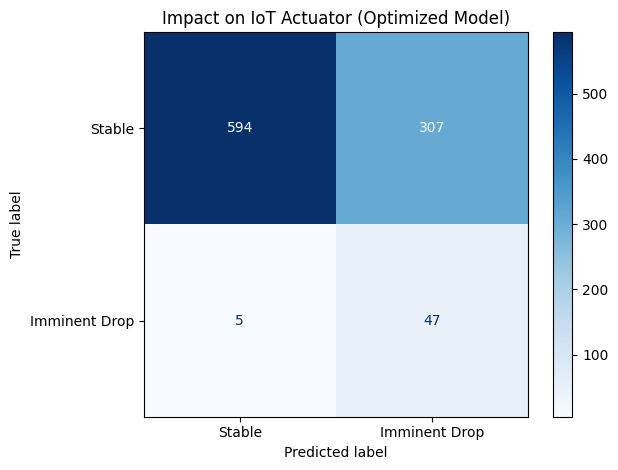

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred = model.predict(test_features).argmax(axis=1)
y_true = test_labels.argmax(axis=1)

print("\n=== POST-SMOTE CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=CLASS_NAMES,
    cmap='Blues'
)
plt.title('Impact on IoT Actuator (Optimized Model)')
plt.tight_layout()
plt.show()

### 8. Model Conversion for IoT using emlearn
*We convert our trained Keras neural network model into a pure C header file to integrate it directly into the Smart Actuator.*

In [23]:
!pip install emlearn

In [24]:
import emlearn
import os

path = 'smart_battery_model.h'

# Convert the Keras neural network into an inline .h file for the C compiler
cmodel = emlearn.convert(model, method='inline')
cmodel.save(file=path, name='smart_battery')

size_bytes = os.path.getsize(path)
nrf52840_ram = 256 * 1024  # bytes

print(f'Model saved to: {path}')
print(f'C file size: {size_bytes / 1024:.1f} KB ({size_bytes:,} bytes)')
print(f'Dongle RAM utilization: {size_bytes / nrf52840_ram * 100:.2f}%')

Model saved to: smart_battery_model.h
C file size: 9.9 KB (10,134 bytes)
Dongle RAM utilization: 3.87%


### 9. Dataset Export for Simulation Replay (Cooja)
*We isolate a 50-timestep window centered around the very first recorded power drop event. This data is structured into a C header file (`dataset_replay.h`) to serve as a simulation for our nodes in Cooja.*

In [25]:
# Find the index of the first drop using labels_1d (since df.pop removed it from the dataframe)
crash_index = np.where(labels_1d == 1)[0][0]

start_step = max(0, crash_index - 10)  # Capture 10 steps prior to the drop for baseline stability
end_step = start_step + 50
df_replay = df.iloc[start_step:end_step]

# Generate C programming language syntax
c_header = "/* Automatically generated by Python - Simulation Replay Dataset */\n\n"
c_header += f"#define REPLAY_STEPS {len(df_replay)}\n\n"

# AC Power Array
ac_power_vals = ", ".join([f"{x:.2f}" for x in df_replay['AC_POWER']])
c_header += f"float ac_power_array[REPLAY_STEPS] = {{{ac_power_vals}}};\n\n"

# Solar Irradiation Array
irr_vals = ", ".join([f"{x:.4f}" for x in df_replay['IRRADIATION']])
c_header += f"float irradiation_array[REPLAY_STEPS] = {{{irr_vals}}};\n\n"

# Module Temperature Array
temp_vals = ", ".join([f"{x:.2f}" for x in df_replay['MODULE_TEMPERATURE']])
c_header += f"float module_temp_array[REPLAY_STEPS] = {{{temp_vals}}};\n\n"

# Save the header file
with open('dataset_replay.h', 'w') as f:
    f.write(c_header)

print("File 'dataset_replay.h' generated successfully!")

File 'dataset_replay.h' generated successfully!
